# Retention time calibration

Map observed retention times to a common scale using standards.

Isotonic regression fits non-decreasing levels. Interpolation between the fitted standards transfers the scale to held-out standards. Evaluation uses calibration and test standards at different retention times inside the calibration range.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from sklearn.isotonic import IsotonicRegression

## Work through the data

The calculation prints its numerical result and plots the observations that produced it.

held-out MAE before 2.276 min | after 0.040 min


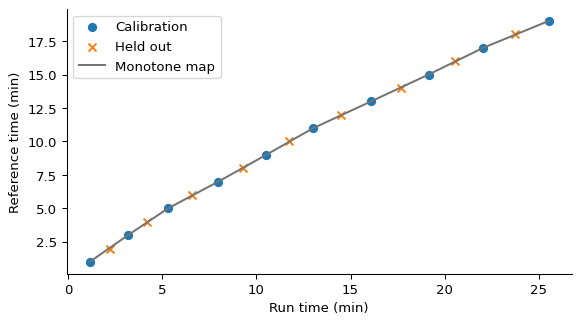

In [2]:
t = np.arange(1.0, 20.0)
lab = t + 0.018 * t * t + 0.15 * np.sin(t)
train = np.arange(len(t)) % 2 == 0
fit = IsotonicRegression(out_of_bounds="clip").fit(lab[train], t[train])
pred = fit.predict(lab[~train])
before = np.mean(abs(lab[~train] - t[~train]))
after = np.mean(abs(pred - t[~train]))
print(f"held-out MAE before {before:.3f} min | after {after:.3f} min")
assert after < before
fig, ax = plt.subplots(figsize=(6, 3.3), constrained_layout=True)
ax.scatter(lab[train], t[train], label="Calibration")
ax.scatter(lab[~train], t[~train], marker="x", label="Held out")
ax.plot(lab, fit.predict(lab), color="0.45", label="Monotone map")
ax.set(xlabel="Run time (min)", ylabel="Reference time (min)")
ax.legend()
plt.show()

## Interpreting the result

The error describes held-out standards within the fitted range. New chemistry or a reversed elution order can violate the model.

## Exercise

Remove alternate calibration points and inspect where residuals grow.

## References

[scikit-learn, isotonic regression](https://scikit-learn.org/stable/modules/isotonic.html)